In [82]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt


<hr color=white>

### <font color='#ff1313'>**Problems in the Dataset**</font>

<strong>1. Original file dose not give DateTime column any name</strong><br>
<strong>2. Original file represent float as "14,5" instead of 14.5</strong><br>
<hr color=white>

### <font color="#33ff00">Fixing the problem :</font>

In [83]:
dir_path = r"/home/knight/Desktop/project_x/electricityloaddiagrams20112014"
file_path = os.path.join(dir_path,"LD2011_2014.txt")


In [ ]:

with open(file_path , "r") as file : # read the file 
    content = file.read()
    content = content.replace('""' , '"DateTime"') # Give `datetime` column name by replace the empty text with "DateTime"
    content = content.replace(',' , '.')           # Replace the comma with a point, so the Pandas parser could cast it to `float64`

with open(file_path , "w") as file :
    file.write(content)

del content

In [84]:
# Load the Dateset
df = pd.read_csv(file_path , delimiter=";")


#### **Note : `datetime` column is loaded as `object` type (`string`) , so it requires type casting.**

In [85]:
df['DateTime'] = pd.to_datetime(df['DateTime']) # change `DateTime` column type from `object` to `DateTime`
df = df.set_index('DateTime')                   # set datetime as the index


<hr color=white>
<hr color=white>

# $$Exploratory \space\space Data \space\space Analysis \space\space (EDA)$$


In [5]:
print("[+] Dataset Shape : ",df.shape)
print("[+] The Number of participating consumers since the start of recording : ",(df.loc[df.index[0]] > 0).sum())
print("[+] The Number of consumers who participated subsequently : ",(df.loc[df.index[0]] == 0).sum())

[+] Dataset Shape :  (140256, 370)
[+] The Number of participating consumers since the start of recording :  158
[+] The Number of consumers who participated subsequently :  212


In [37]:
df.iloc[:,[170]]

,MT_171
DateTime,
2011-01-01 00:15:00,137.885196
2011-01-01 00:30:00,150.030211
2011-01-01 00:45:00,153.051360
2011-01-01 01:00:00,156.102719
2011-01-01 01:15:00,146.978852
...,...
2014-12-31 23:00:00,137.885196
2014-12-31 23:15:00,134.864048
2014-12-31 23:30:00,125.770393


In [6]:
# Examples of some consumers at a period of time
df.iloc[110000:110010,100:107]

,MT_101,MT_102,MT_103,MT_104,MT_105,MT_106,MT_107
DateTime,,,,,,,
2014-02-19 20:15:00,763.066202,1109.643329,1671.186441,615.841584,302.300110,42.735043,22.484542
2014-02-19 20:30:00,797.909408,1085.865258,1603.389831,611.881188,237.130340,38.936372,28.667791
2014-02-19 20:45:00,785.714286,1060.766182,1583.050847,616.831683,208.105148,41.785375,26.419337
2014-02-19 21:00:00,768.292683,1031.704095,1593.220339,613.861386,201.533406,39.886040,22.484542
2014-02-19 21:15:00,763.066202,993.394980,1577.966102,608.910891,197.152245,37.986705,19.111861
2014-02-19 21:30:00,796.167247,993.394980,1559.322034,613.861386,199.342826,37.986705,19.673974
2014-02-19 21:45:00,752.613240,994.715984,1567.796610,608.910891,198.795181,39.886040,19.673974
2014-02-19 22:00:00,777.003484,841.479524,1525.423729,602.970297,189.485214,38.936372,19.111861
2014-02-19 22:15:00,729.965157,647.291942,1311.864407,469.306931,182.913472,34.188034,19.111861


<hr color=white>

# **Dataset Description**
- **This dataset contain 370 records for 370 consumers**
- **Each consumer represent a pattern of consumption in the dataset**
- **Each record consists of 140,256 time points, separated by 15-minute intervals.**
- **Recording start at 2011-1-1 and end at 2015-1-1**
- **Each point represent the consumption of the electricity at a specific moment in time for specific consumer in `KW` unit**
- **Some consumers participated after 2011, in these cases consumption were considered zero.**
<hr color=white>

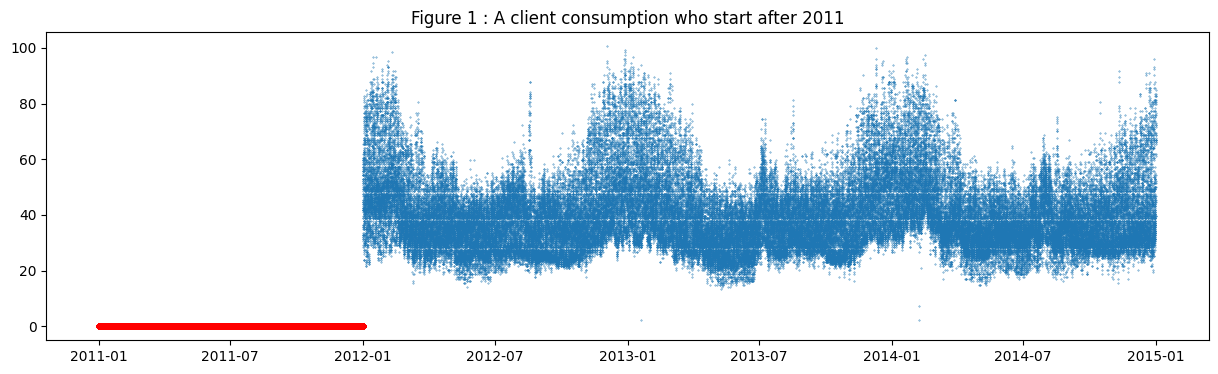

In [248]:
# Example of an client consumption who start at 2012
#----------------------------------------------------
n = 10
data = df.loc["2011-01-01 00:00:00":"2015-01-10 00:00:00"]
plt.figure(figsize=(15, 4) )
plt.title("Figure 1 : A client consumption who start after 2011")
plt.scatter(
    data.index,
    data.values[:,n],
    s=0.1)


zero_points = data.values[:,n] == 0
plt.scatter(
    data.index[zero_points],
    data.values[:,n][zero_points],
    color="red",
    s=10,
    label="Zeros",
)
plt.show()

In [11]:
print("[+] Number of Duplicated: ",df.duplicated().sum())

[+] Number of Duplicated:  0


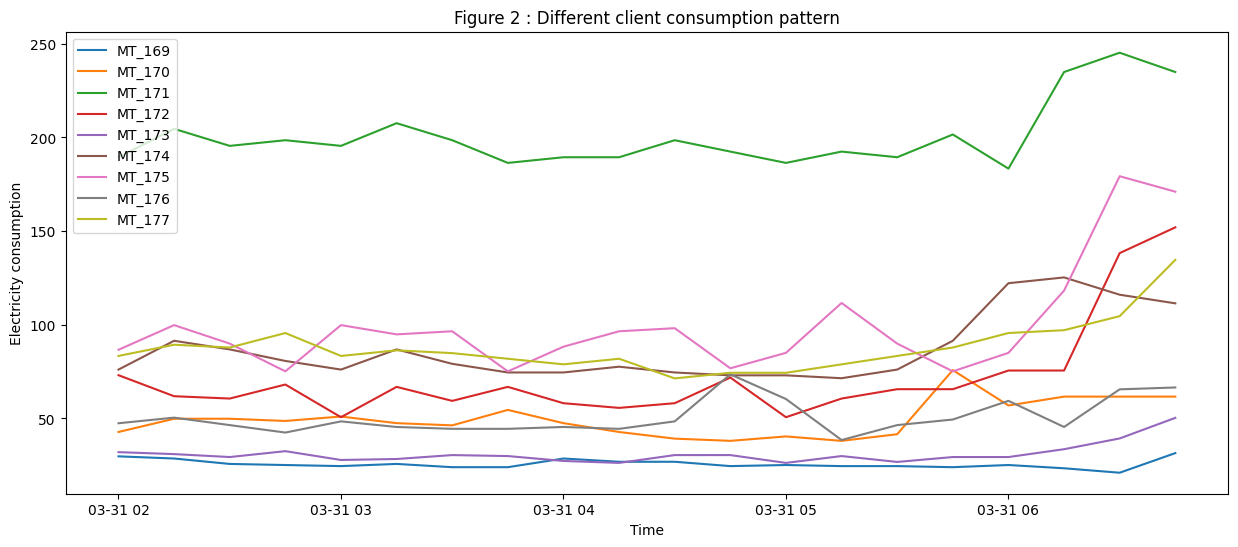

In [15]:
# Display some examples of client Electricity Consumption at a period of time
#-----------------------------------------------------------------------------
consumer_num = 168
series_len = 20
series_start = 113727-(35000*1)
data = df.iloc[series_start:series_start+series_len , consumer_num:consumer_num+9]

plt.figure(figsize=(15, 6))

for col in data.columns:
    plt.plot(data.index, data[col], label=col)

plt.title("Figure 2 : Different client consumption pattern")
plt.xlabel("Time")
plt.ylabel("Electricity consumption")
plt.legend()
plt.show()


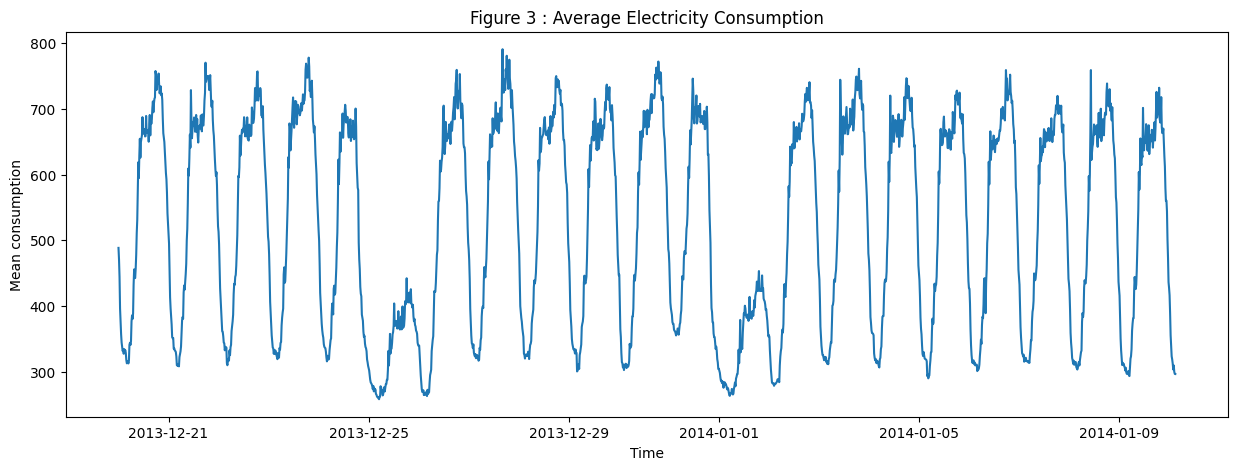

In [16]:
# Display the average Electricity consumption over all clients at a period of time
#----------------------------------------------------------------------------------
start = "2013-12-20 00:00:00" ; end = "2014-01-10 3:00:00"
mean_consumption = df.mean(axis=1).loc[start:end]
plt.figure(figsize=(15, 5))
plt.plot(mean_consumption.index, mean_consumption)
plt.xlabel("Time")
plt.ylabel("Mean consumption")
plt.title("Figure 3 : Average Electricity Consumption")
plt.show()

<hr color=white>

### **NOTE:**
**1. On the daylight saving time (DST) transition day in March, which has only 23 hours, the values between 1:00 AM and 2:00 AM are reported as zero for all points.**<br>
**2. On the daylight saving time (DST) transition day in October, which has 25 hours, the values between 1:00 AM and 2:00 AM represent the aggregated consumption of two hours.**<br>

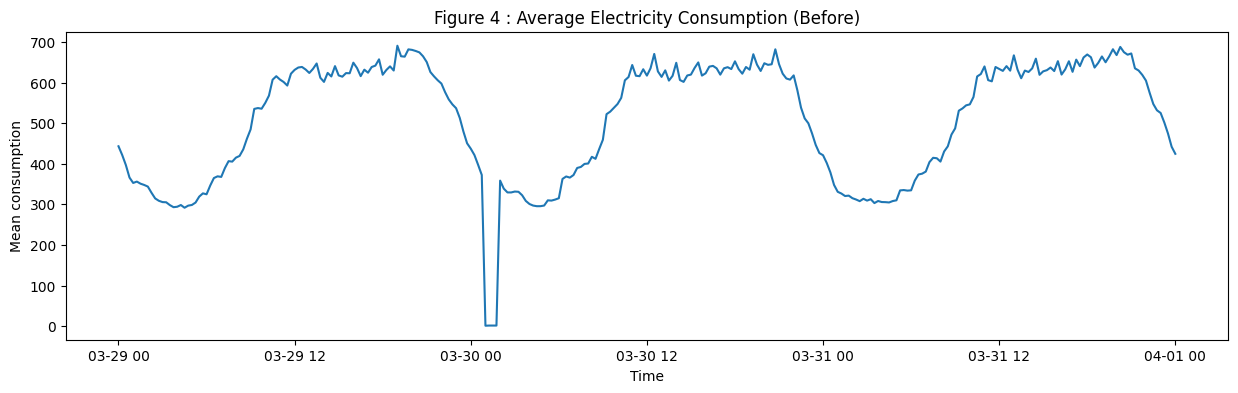

In [18]:
# Display the average consumption at DST Before handling the error
#------------------------------------------------------------------
start = "2014-03-29 00:00:00" ; end = "2014-04-01 0:00:00"
mean_consumption = df.mean(axis=1).loc[start:end]
plt.figure(figsize=(15, 4))
plt.plot(mean_consumption.index, mean_consumption)
plt.xlabel("Time")
plt.ylabel("Mean consumption")
plt.title("Figure 4 : Average Electricity Consumption (Before)")
plt.show()


### **<font color="#33ff00">How It will Handled:</font>**

* **March:** Zero values caused by the DST transition were replaced with the average of the previous and next points.
* **October:** The aggregated values during the DST transition were also replaced with the average of the previous and next points.


In [87]:

march_dates   = [ '2014-03-30', '2013-03-31', '2012-03-25' ]
october_dates = [ '2014-10-26', '2013-10-27', '2012-10-28' ]
all_dates = march_dates + october_dates
columns = df.columns

for date in all_dates:        
    previous_time = pd.Timestamp(f'{date} 00:45:00')
    next_time     = pd.Timestamp(f'{date} 02:00:00')

    previous_value = df.loc[previous_time, columns] # Get Previous point
    next_value     = df.loc[next_time, columns]     # Get Next point


    estimated_value = (previous_value + next_value) / 2


    mask = ((df.index >= pd.Timestamp(f'{date} 01:00:00')) &
            (df.index <= pd.Timestamp(f'{date} 01:45:00'))   )  # Update only the values in specific interval

    n_rows = mask.sum()
    df.loc[mask, columns] = np.tile(estimated_value.to_numpy(),(n_rows, 1))
    


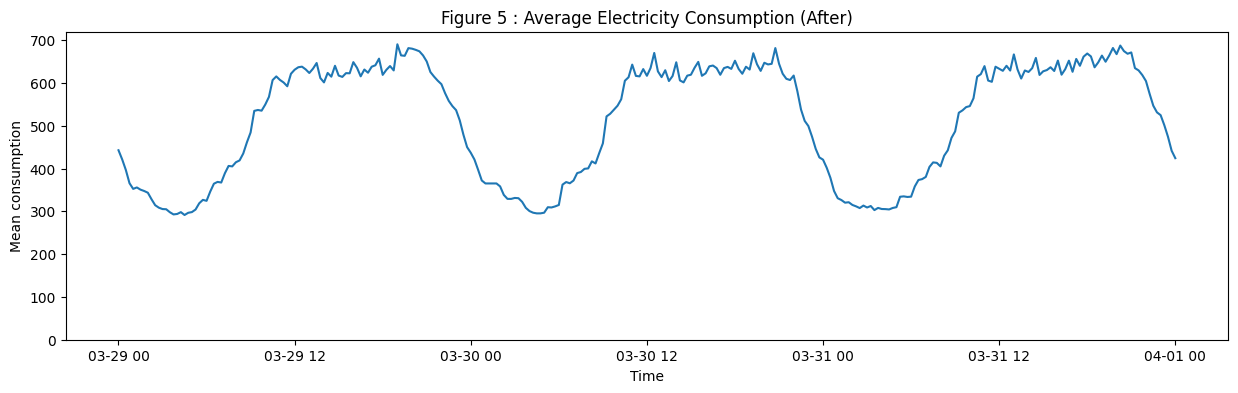

In [14]:
# Display the average consumption at DST After handling the error
#------------------------------------------------------------------
start = "2014-03-29 00:00:00" ; end = "2014-04-01 0:00:00"
mean_consumption = df.mean(axis=1).loc[start:end]
plt.figure(figsize=(15, 4))
plt.plot(mean_consumption.index, mean_consumption)
plt.ylim((0,720))
plt.xlabel("Time")
plt.ylabel("Mean consumption")
plt.title("Figure 5 : Average Electricity Consumption (After)")
plt.show()

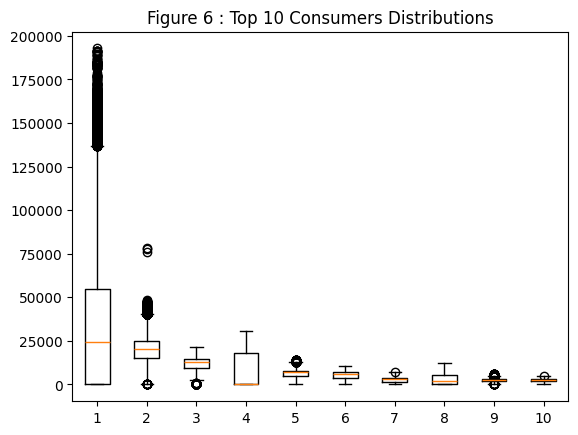

In [22]:
# Box-Plot for the top 10 consumers
#------------------------------------
consumer_mean = df.mean(axis=0)
top_consumers = consumer_mean.nlargest(10).index
plt.boxplot(df[top_consumers])
plt.title("Figure 6 : Top 10 Consumers Distributions")
plt.show()


<hr color=white>

### **PLAN:**
**1. First thing we would do is to split the DataFrame into 370 DataFrame**<br>
**2. So each consumer will be in a separated dataframe to preprocessing and feature engineering**<br>
**3. After feature engineering each consumer (DataFrame), DataFrames will be combined to use it in training the AI Model.**<br>

<hr>

In [79]:
dfs = [df[[column]] for column in df.columns] # split the DataFrame into DataFrames (DataFrame for each consumer)
print(len(dfs)) # number of DataFrames (Number of Consumers)

370


In [80]:
dfs_trimmed = [] # list to hold new DataFrames after trimming (Removing leading zeros)

for data in dfs: # loop all DataFrames
    column = data.columns[0] # Get column name [ MT0_001, MT0_002, MT0_003   ....   MT0_370 ]

    non_zero = data[column].ne(0) # Find Non-zero points
    
    if non_zero.any(): # if the series has at least one non-zero value
        first_valid = non_zero.idxmax() # Get first non-zero index (since all values are `1` the index of the maximum number will be the first one in the series)
        data = data.loc[first_valid:]   # Trim the series
    dfs_trimmed.append(data)

# DataFrames have different length now after trimming it

MT_101    428
dtype: int64
MT_102    684
dtype: int64
MT_103    0
dtype: int64
MT_104    0
dtype: int64


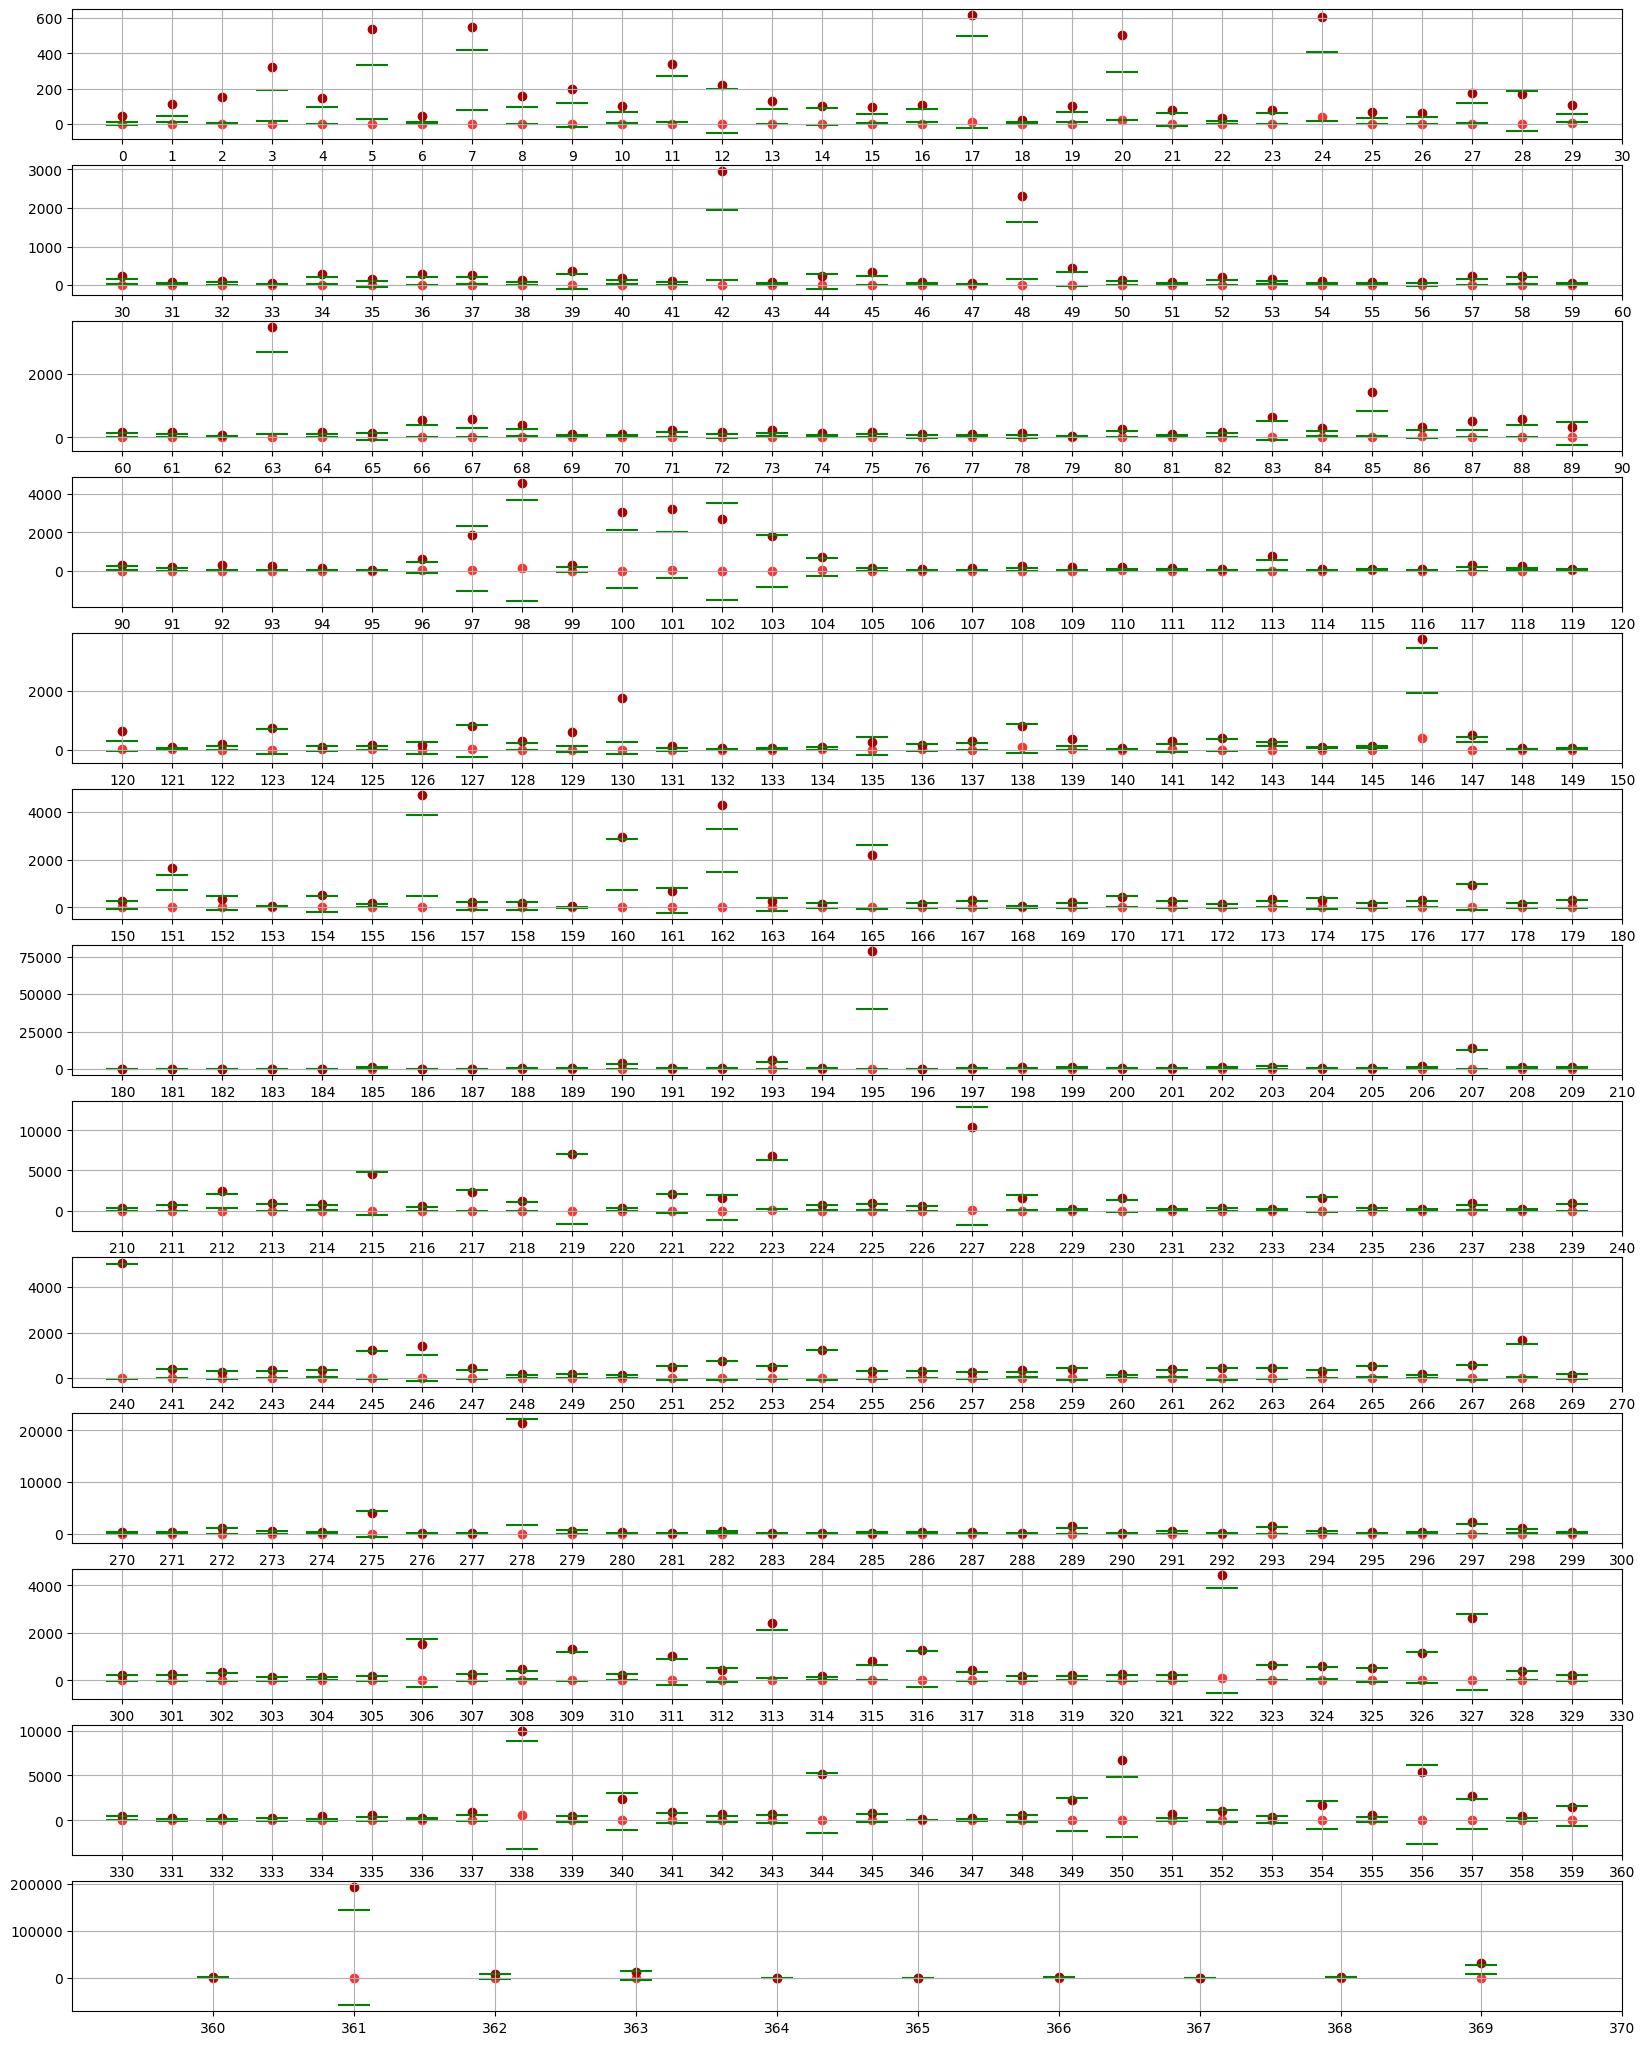

In [ ]:

Q1 = pd.Series(data=[ float(_df.quantile(0.25).iloc[0]) for _df in dfs_trimmed])
Q3 = pd.Series(data=[ float(_df.quantile(0.75).iloc[0]) for _df in dfs_trimmed])

IQR = Q3-Q1
min_boundaries = Q1 - IQR*1.5
max_boundaries = Q3 + IQR*1.5


min_values = [_df.min().iloc[0] for _df in dfs_trimmed]
max_values = [_df.max().iloc[0] for _df in dfs_trimmed]


for index , _df in enumerate(dfs_trimmed):
    if index in [100,101,102,103]:
        print(((_df<min_boundaries[index]) | (_df>max_boundaries[index])).sum())
    



start = 0
end = 30
number_of_iter = int(370/end+0.999)

plt.figure(figsize=(20,2*number_of_iter))
for i in range(1,number_of_iter+1):
    plt.subplot(number_of_iter,1,i)
    length = min_values[start:end].__len__()
    plt.scatter(range(start,start+length) , min_values[start:end] , color="#ff3232")
    plt.scatter(range(start,start+length) , max_values[start:end] , color="#a90000")
    plt.scatter(range(start,start+length) , max_boundaries[start:end] , color="green" , s=500 , marker="_")
    plt.scatter(range(start,start+length) , min_boundaries[start:end] , color="green" , s=500 , marker="_")
    
    plt.grid()
    plt.xlim(start-1, start+length )
    plt.xticks(range(start , start+length + 1))
    start +=30
    end +=30

plt.show()




In [ ]:
dfs_trimmed[0].head() # Display first DataFrame (Start at `2012`)


,MT_001
DateTime,
2012-01-01 00:15:00,3.807107
2012-01-01 00:30:00,5.076142
2012-01-01 00:45:00,3.807107
2012-01-01 01:00:00,3.807107
2012-01-01 01:15:00,5.076142


10560
55071
55238


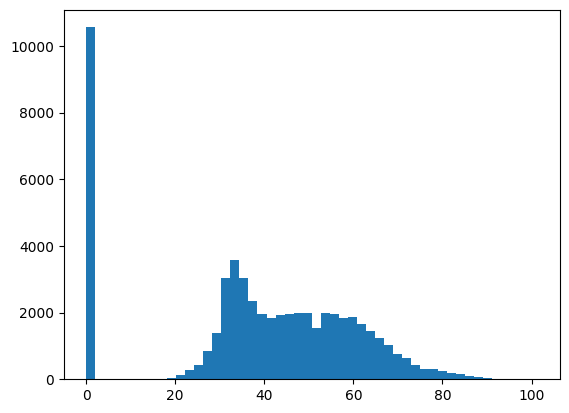

In [249]:
data = dfs_trimmed[14]
print((data==0).sum().sum())
print(data.duplicated().sum())
print(data.__len__())
dfs_trimmed[0]
# Example of an client consumption who start at 2012
#----------------------------------------------------

plt.hist(data[data.columns[0]],bins=50)


plt.show()

<hr>

**Since the forecasting model will operate on an hourly time resolution,**<br>
**each consumer's time series is resampled from 15-minute intervals to 1-hour intervals.**

In [8]:
dfs_hourly = [ consumer.resample('1h').mean()  for consumer in dfs_trimmed ]
dfs_hourly[170].head()

,MT_171
DateTime,
2011-01-01 00:00:00,146.988922
2011-01-01 01:00:00,151.540785
2011-01-01 02:00:00,143.202417
2011-01-01 03:00:00,140.158610
2011-01-01 04:00:00,140.929003


<hr color=white>
<hr color=white>

# $$Feature \space\space Engineering \space\space Part$$


The Target (output) of the AI Model is the forecast of the customer's next hour of consumption.<br>
To help the model to forecast, **The Model will be provided with `168` hours prior to the target time.**<br>

For More Feature Enrichment<br>
The model will be provided with :<br>
* **The month that corresponding to the target time**
* **The day_of_week that corresponding to the target time**
* **The hour_of_day that corresponding to the target time**

**why 168 ?**<br>
`168` hour represent the whole week, and since the same hour in the previous week highly correlated with the target hour<br>
feeding the model with the last `168` hour could reveal the pattern to the model


# **<font color="#ff1919">Warning</font>**

* <font color="#fffb18">The code below will result a huge amont of data that could excees <font color="#ff1919">27 GB</font> located on the Hard Disk</font><br>
* <font color="#fffb18">To Contral the amount of data generated, higher `limit` variable will result bigger amount of data</font>

In [ ]:


result_folder = r"/home/knight/Desktop/project_x/results"
try:os.mkdir(result_folder)
except:pass
print("Number of DataFrames : 370")
counter = 0
limit = 20  #  Each DataFrame could result 100 MB of data approximately
verbos = 1  #  ( 1:Print result as it generated ) | () 0:Print only final result )
_limit = limit
number_of_examples = 0
for consumer_df in dfs_hourly: # loop the DataFrames
    counter +=1
    limit -= 1
    
    consumer = consumer_df.columns[0]
    data = consumer_df.copy()
    data = data.rename(columns={consumer: 'target'})      # Set the target time
    lags = pd.concat(
        [data['target'].shift(i) for i in range(1, 169)], # Specify the cilent consumption in the last 168 hour
        axis=1
    )

    lags.columns = [f't-{i}' for i in range(1, 169)]  # Rename the columns to (t-1 , t-2 , ... , t-168)

    data['month'] = data.index.month         # Extract The month that corresponding to the target time
    data['dayofweek'] = data.index.dayofweek # Extract The dayofweek that corresponding to the target time
    data['hour'] = data.index.hour           # Extract The hourofday that corresponding to the target time
    data = pd.concat([data, lags], axis=1)
    
    data = data.dropna()  # delete the null values that coused be the lag (shift)
    # gg = data.iloc[:,4:]
    # print((gg == 0).sum())
    # print(gg.__len__())

    print(f"[{consumer}] Zeros : ",(data == 0).sum())


    number_of_examples += data.shape[0]
    result_path = os.path.join(result_folder , f"{consumer}.csv")
    data.to_csv(result_path , index=False)
    if verbos : print(f"[{counter:03d}/{(_limit if _limit<370 else 370)}] Extract {data.shape[0]} Examples ...... Results saved in '{consumer}.csv'")
    if limit == 0:print("[-] Exiting ....");break
    
print("Final Result :")
print(f"[+] All Results saved in {result_folder}.")
print(f"[+] Complete {counter} DataFrame.")
print(f"[+] The Process results {number_of_examples} Examples, that could be used to train the AI model.")


Number of DataFrames : 370
[MT_001] Zeros :  37
[001/20] Extract 26137 Examples ...... Results saved in 'MT_001.csv'
[MT_002] Zeros :  0
[002/20] Extract 26137 Examples ...... Results saved in 'MT_002.csv'
[MT_003] Zeros :  147
[003/20] Extract 26137 Examples ...... Results saved in 'MT_003.csv'
[MT_004] Zeros :  0
[004/20] Extract 26137 Examples ...... Results saved in 'MT_004.csv'
[MT_005] Zeros :  0
[005/20] Extract 26137 Examples ...... Results saved in 'MT_005.csv'
[MT_006] Zeros :  0
[006/20] Extract 26137 Examples ...... Results saved in 'MT_006.csv'
[MT_007] Zeros :  0
[007/20] Extract 26137 Examples ...... Results saved in 'MT_007.csv'
[MT_008] Zeros :  0
[008/20] Extract 26137 Examples ...... Results saved in 'MT_008.csv'
[MT_009] Zeros :  0
[009/20] Extract 26137 Examples ...... Results saved in 'MT_009.csv'
[MT_010] Zeros :  0
[010/20] Extract 26137 Examples ...... Results saved in 'MT_010.csv'
[MT_011] Zeros :  0
[011/20] Extract 26137 Examples ...... Results saved in 'MT_

147


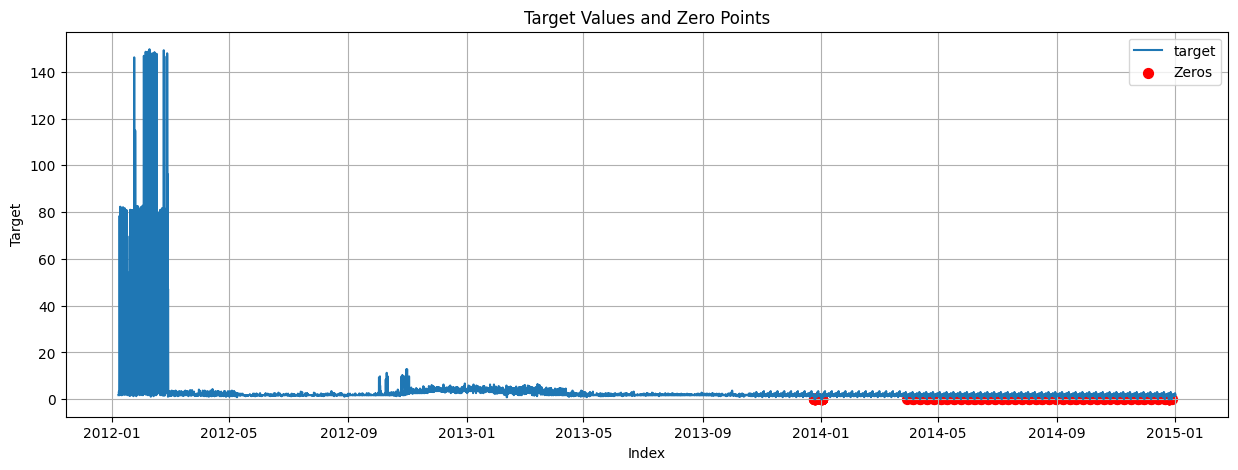

In [99]:
import matplotlib.pyplot as plt

print((data["target"]==0).sum())


plt.figure(figsize=(15, 5))

plt.plot(data.index, data["target"], label="target")

# تحديد أماكن الأصفار
zero_points = data["target"] == 0

plt.scatter(
    data.index[zero_points],
    data["target"][zero_points],
    color="red",
    s=50,
    label="Zeros"
)

plt.xlabel("Index")
plt.ylabel("Target")
plt.title("Target Values and Zero Points")
plt.legend()
plt.grid(True)

plt.show()

In [139]:
# Display an example of the result
#-----------------------------------
data.index = range(len(data))

# data.iloc[24020,:15]
data[data==0]

,target,month,dayofweek,hour,t-1,t-2,t-3,t-4,t-5,t-6,...,t-159,t-160,t-161,t-162,t-163,t-164,t-165,t-166,t-167,t-168
0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26132,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
26133,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
26134,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
26135,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
